# Supply chain digital twin – CA_1, FOODS_3

Goal: stress-test the Phase 2 inventory policies in a supplier → DC → store network with
disruptions, using a discrete-event simulation in SimPy.

## How SimPy works: a toy model

One item, one store, one supplier. Demand is 10 units a day; every 7 days the store orders
up to 120 units; deliveries take `lead_time` days.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import simpy

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


def run_toy(
    days=42, demand=10, start_stock=50, order_up_to=120, lead_time=3, outage=None, verbose=True
):
    """One item, one store, one supplier. outage = (first_day, last_day) the supplier is down."""
    env = simpy.Environment()
    state = {"stock": start_stock, "on_order": 0}
    daily = []

    def say(event, units):
        if verbose:
            print(f"day {env.now:>3}: {event:<9} {units:>4} units   stock {state['stock']:>4}")

    def delivery(units):
        """A truck: wait while the supplier is down, then the lead time, then unload."""
        if outage and outage[0] <= env.now <= outage[1]:
            yield env.timeout(outage[1] + 1 - env.now)
        yield env.timeout(lead_time)
        state["stock"] += units
        state["on_order"] -= units
        say("delivered", units)

    def store():
        """Every day: on day 0, 7, 14... order up to `order_up_to`, then sell."""
        while True:
            if env.now % 7 == 0:
                units = max(0, order_up_to - state["stock"] - state["on_order"])
                if units:
                    state["on_order"] += units
                    say("ordered", units)
                    env.process(delivery(units))
            sold = min(state["stock"], demand)
            state["stock"] -= sold
            if sold < demand:
                say("lost", demand - sold)
            daily.append({"day": env.now, "stock": state["stock"], "lost": demand - sold})
            yield env.timeout(1)

    env.process(store())
    env.run(until=days)
    return pd.DataFrame(daily)

In [4]:
run_toy(days=15);

day   0: ordered     70 units   stock   50
day   3: delivered   70 units   stock   90
day   7: ordered     70 units   stock   50
day  10: delivered   70 units   stock   90
day  14: ordered     70 units   stock   50


day   0: ordered    120 units   stock   50
day   5: lost        10 units   stock    0
day   6: lost        10 units   stock    0
day   7: ordered     50 units   stock    0
day   7: lost        10 units   stock    0
day   8: lost        10 units   stock    0
day   9: delivered  120 units   stock  120
day  14: ordered     50 units   stock   70
day  16: delivered   50 units   stock  100
day  21: ordered     70 units   stock   50
day  23: delivered   50 units   stock   80
day  28: ordered     70 units   stock   30
day  30: delivered   70 units   stock   80
day  35: ordered     70 units   stock   30
day  37: delivered   70 units   stock   80


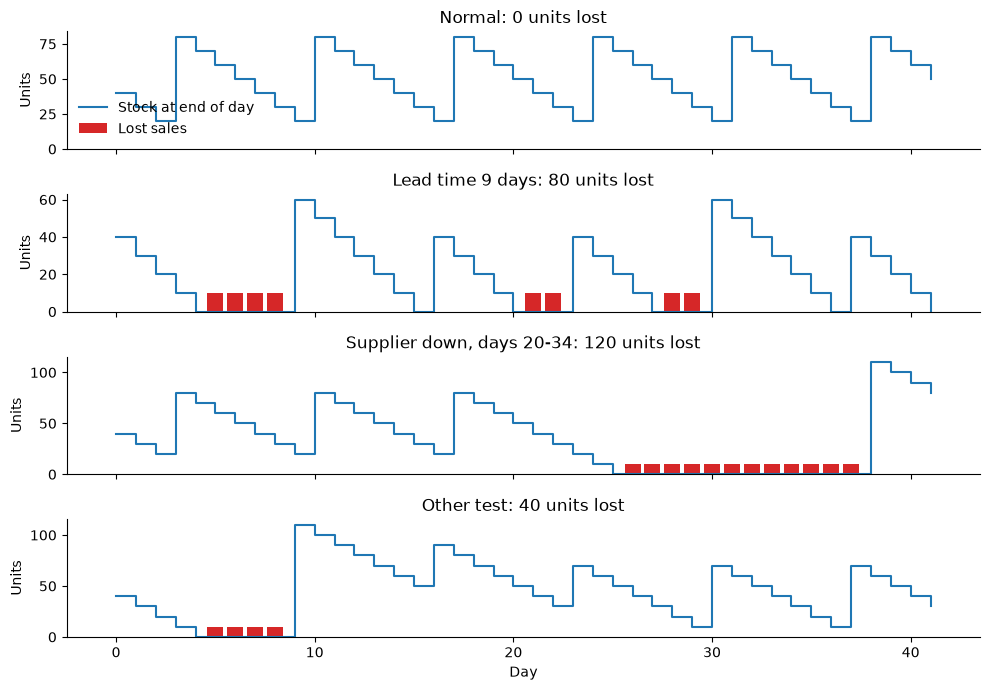

In [7]:
runs = {
    "Normal": run_toy(verbose=False),
    "Lead time 9 days": run_toy(lead_time=9, verbose=False),
    "Supplier down, days 20-34": run_toy(outage=(20, 34), verbose=False),
    "Other test": run_toy(order_up_to=170, lead_time=9),
}

fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, (name, d) in zip(axes, runs.items()):
    ax.plot(d["day"], d["stock"], drawstyle="steps-post", label="Stock at end of day")
    ax.bar(d["day"], d["lost"], color="tab:red", label="Lost sales")
    ax.set_title(f"{name}: {d['lost'].sum()} units lost")
    ax.set_ylabel("Units")
axes[0].legend(frameon=False)
axes[-1].set_xlabel("Day")
plt.tight_layout()
plt.show()